In [1]:
from pathlib import Path
import pandas as pd

project = Path.home() / "Documents" / "BSE_Climate_Policy"
panel_file = (
    project / "processed_data"
    / "research_panel_draft_with_climate_patents_2000_2019.csv"
)
panel = pd.read_csv(panel_file)

renew_change = (
    panel[panel["year"].isin([2000, 2019])]
    .pivot(index="country_code", columns="year", values="renewable_share")
    .rename(columns={2000: "renewable_2000", 2019: "renewable_2019"})
)

renew_change["change_percentage_points"] = (
    renew_change["renewable_2019"] - renew_change["renewable_2000"]
)

display(renew_change.round(1))

year,renewable_2000,renewable_2019,change_percentage_points
country_code,,,
AUS,8.4,10.3,1.9
CAN,20.3,22.4,2.1
DEU,3.7,17.1,13.4
ESP,7.9,16.7,8.8
FRA,9.3,15.5,6.2
GBR,1.0,11.4,10.4
IRL,2.0,12.3,10.3
ITA,5.1,17.3,12.2
MEX,12.2,10.3,-1.9


Matplotlib is building the font cache; this may take a moment.


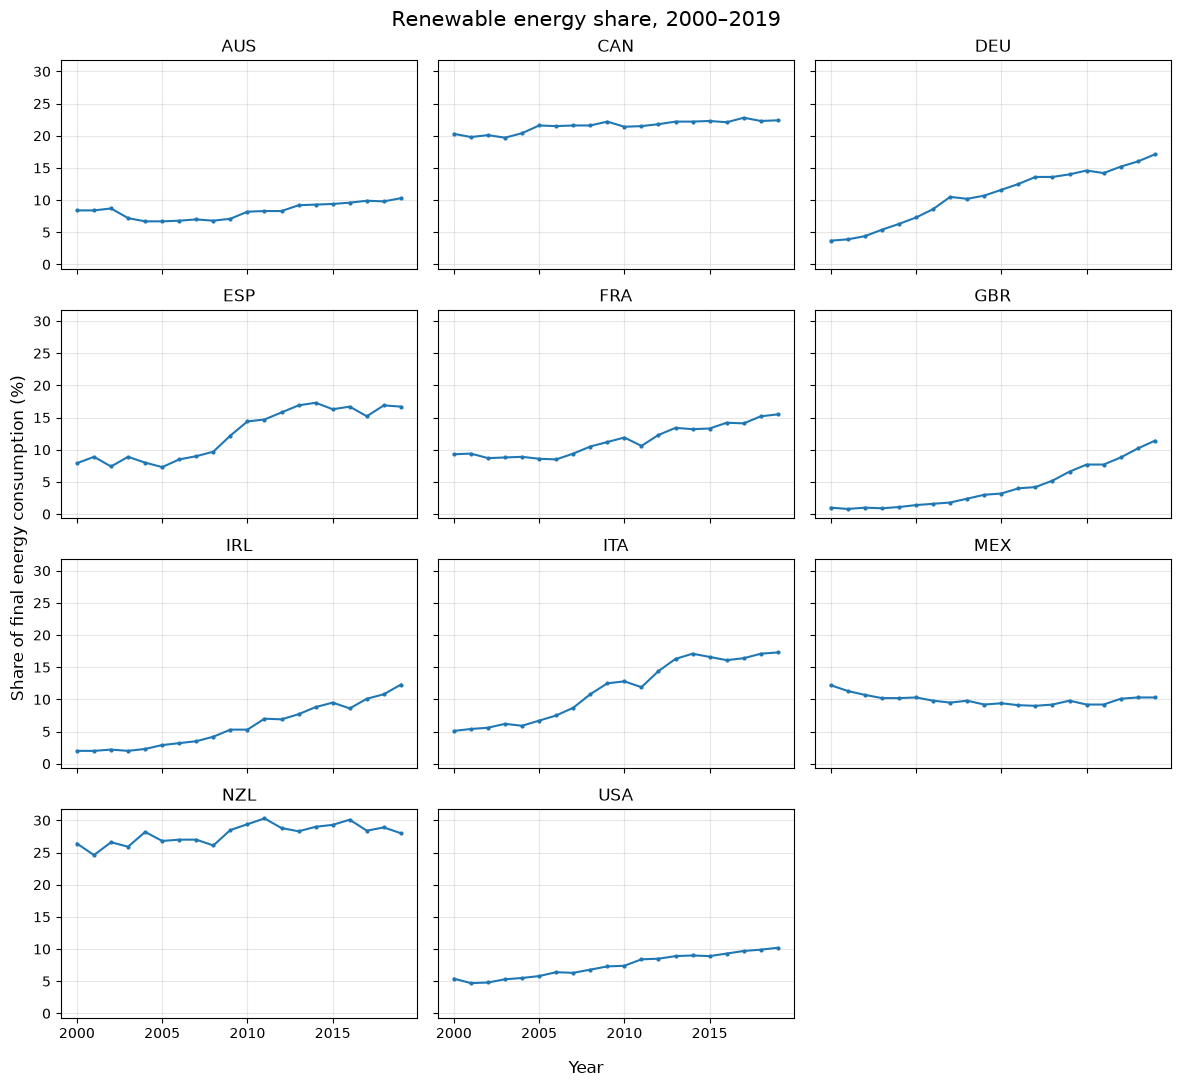

그래프 저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/renewable_share_by_country.png


In [2]:
import matplotlib.pyplot as plt

countries_for_plot = sorted(panel["country_code"].unique())
fig, axes = plt.subplots(4, 3, figsize=(12, 11), sharex=True, sharey=True)

for ax, country in zip(axes.flat, countries_for_plot):
    country_data = panel[panel["country_code"] == country]
    ax.plot(
        country_data["year"],
        country_data["renewable_share"],
        marker="o",
        markersize=2
    )
    ax.set_title(country)
    ax.grid(alpha=0.3)

# 11개국이라 남는 12번째 칸 숨기기
for ax in list(axes.flat)[len(countries_for_plot):]:
    ax.axis("off")

fig.suptitle("Renewable energy share, 2000–2019", fontsize=15)
fig.supxlabel("Year")
fig.supylabel("Share of final energy consumption (%)")
fig.tight_layout()

chart_file = project / "outputs" / "renewable_share_by_country.png"
fig.savefig(chart_file, dpi=200, bbox_inches="tight")
plt.show()

print("그래프 저장 완료:", chart_file)

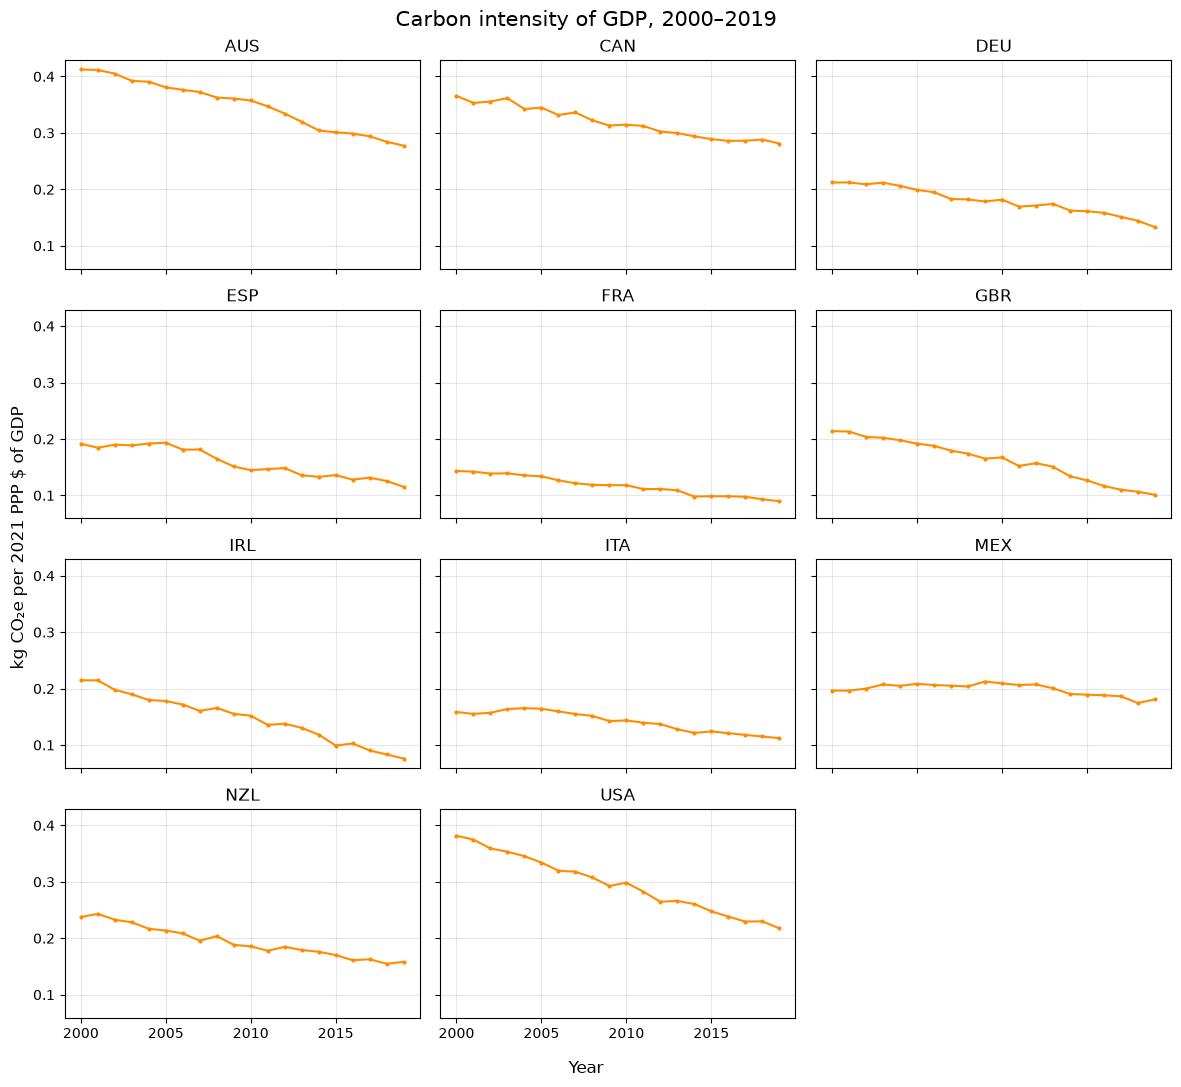

그래프 저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/carbon_intensity_by_country.png


In [3]:
fig, axes = plt.subplots(4, 3, figsize=(12, 11), sharex=True, sharey=True)

for ax, country in zip(axes.flat, countries_for_plot):
    country_data = panel[panel["country_code"] == country]
    ax.plot(
        country_data["year"],
        country_data["carbon_intensity"],
        marker="o",
        markersize=2,
        color="darkorange"
    )
    ax.set_title(country)
    ax.grid(alpha=0.3)

for ax in list(axes.flat)[len(countries_for_plot):]:
    ax.axis("off")

fig.suptitle("Carbon intensity of GDP, 2000–2019", fontsize=15)
fig.supxlabel("Year")
fig.supylabel("kg CO₂e per 2021 PPP $ of GDP")
fig.tight_layout()

chart_file = project / "outputs" / "carbon_intensity_by_country.png"
fig.savefig(chart_file, dpi=200, bbox_inches="tight")
plt.show()

print("그래프 저장 완료:", chart_file)

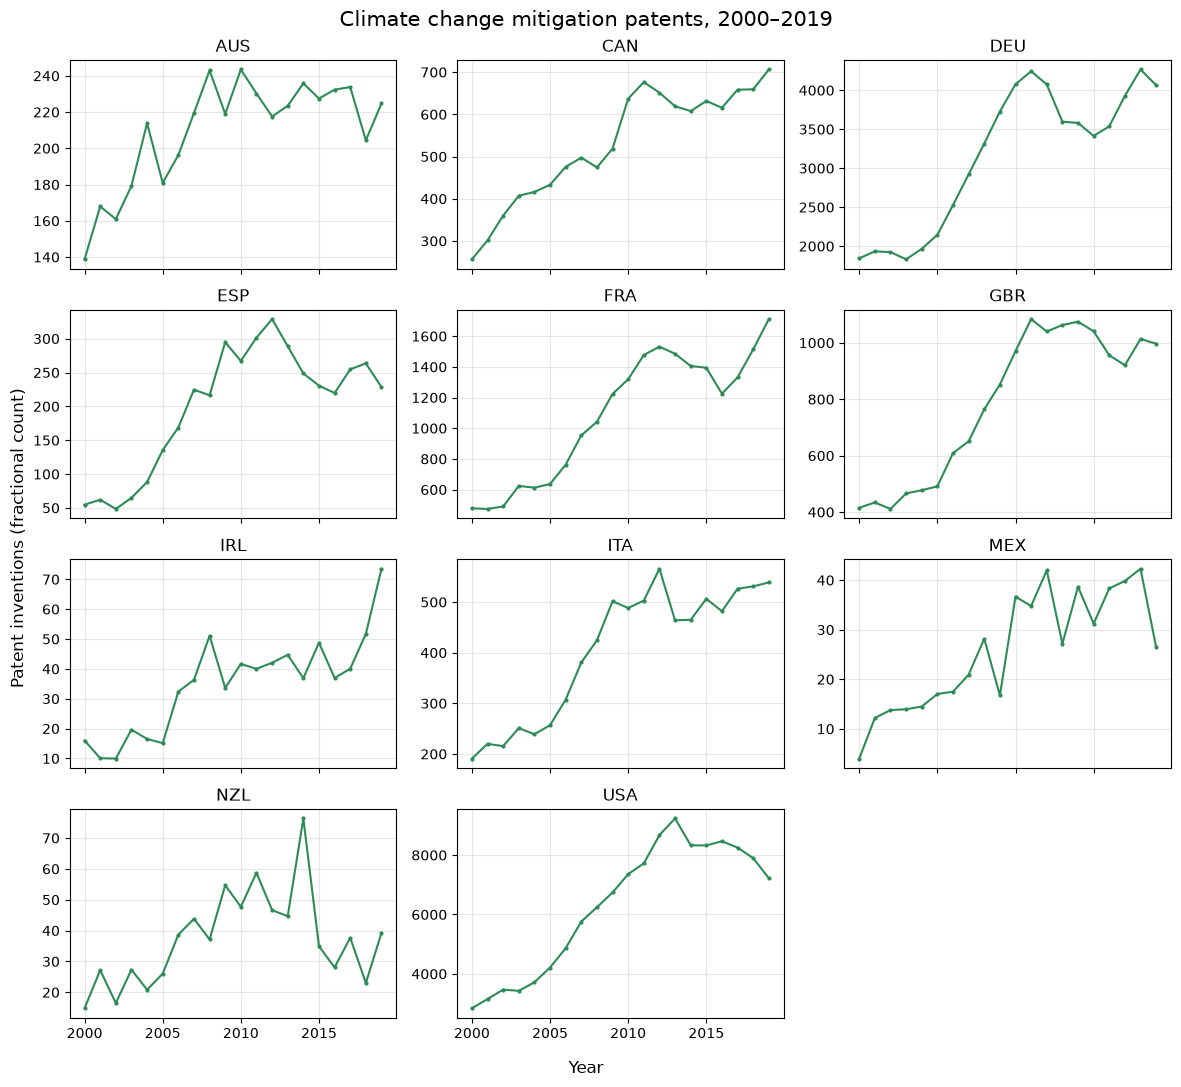

그래프 저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/climate_patents_by_country.png


In [4]:
fig, axes = plt.subplots(4, 3, figsize=(12, 11), sharex=True)

for ax, country in zip(axes.flat, countries_for_plot):
    country_data = panel[panel["country_code"] == country]
    ax.plot(
        country_data["year"],
        country_data["climate_patents"],
        marker="o",
        markersize=2,
        color="seagreen"
    )
    ax.set_title(country)
    ax.grid(alpha=0.3)

for ax in list(axes.flat)[len(countries_for_plot):]:
    ax.axis("off")

fig.suptitle("Climate change mitigation patents, 2000–2019", fontsize=15)
fig.supxlabel("Year")
fig.supylabel("Patent inventions (fractional count)")
fig.tight_layout()

chart_file = project / "outputs" / "climate_patents_by_country.png"
fig.savefig(chart_file, dpi=200, bbox_inches="tight")
plt.show()

print("그래프 저장 완료:", chart_file)

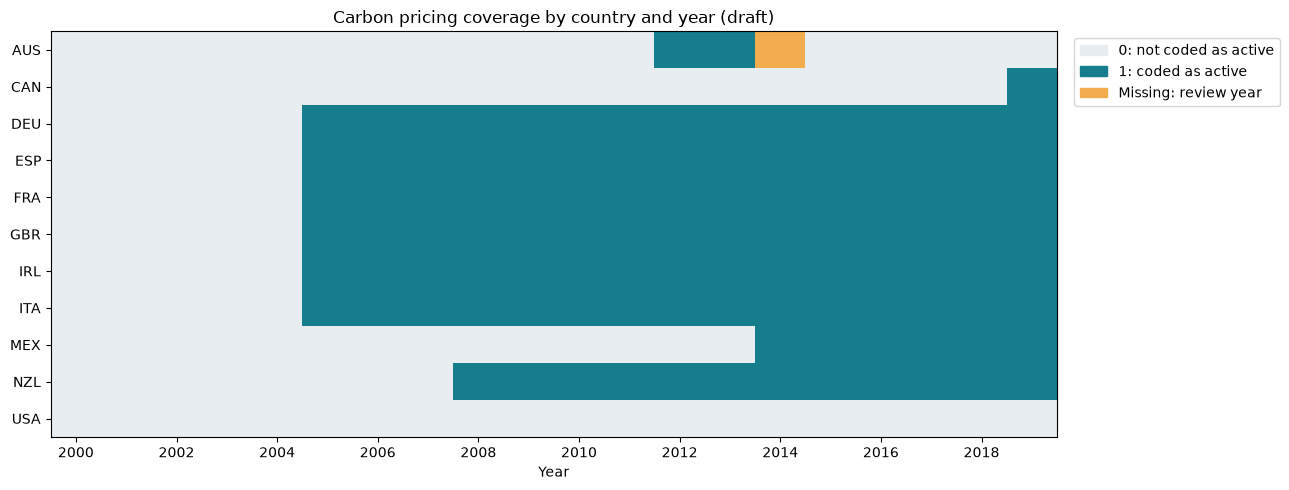

그래프 저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/carbon_policy_timeline_draft.png


In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

policy_grid = (
    panel.pivot(
        index="country_code",
        columns="year",
        values="CarbonPrice_draft"
    )
    .sort_index()
)

colors = ListedColormap(["#e8edf2", "#167d8d"])
colors.set_bad("#f2ad4e")  # 값이 비어 있는 연도

fig, ax = plt.subplots(figsize=(13, 5))
ax.imshow(
    policy_grid.to_numpy(dtype=float),
    aspect="auto",
    cmap=colors,
    vmin=0,
    vmax=1
)

ax.set_yticks(range(len(policy_grid.index)))
ax.set_yticklabels(policy_grid.index)

ax.set_xticks(range(0, len(policy_grid.columns), 2))
ax.set_xticklabels(policy_grid.columns[::2])

ax.set_title("Carbon pricing coverage by country and year (draft)")
ax.set_xlabel("Year")

ax.legend(
    handles=[
        Patch(color="#e8edf2", label="0: not coded as active"),
        Patch(color="#167d8d", label="1: coded as active"),
        Patch(color="#f2ad4e", label="Missing: review year"),
    ],
    loc="upper left",
    bbox_to_anchor=(1.01, 1)
)

fig.tight_layout()

chart_file = project / "outputs" / "carbon_policy_timeline_draft.png"
fig.savefig(chart_file, dpi=200, bbox_inches="tight")
plt.show()

print("그래프 저장 완료:", chart_file)

In [6]:
countries_list = sorted(panel["country_code"].unique())

missing_cpu_years = (
    panel[panel["CPU"].isna()]
    .groupby("country_code")["year"]
    .apply(lambda years: ", ".join(years.astype(str)))
    .reindex(countries_list)
    .fillna("없음")
)

first_cpu_year = (
    panel.dropna(subset=["CPU"])
    .groupby("country_code")["year"]
    .min()
    .reindex(countries_list)
)

required = [
    "CPU", "CarbonPrice_draft",
    "renewable_share", "carbon_intensity", "climate_patents",
    "gdp_per_capita", "trade_pct_gdp", "industry_pct_gdp"
]

usable_years = (
    panel.assign(usable=panel[required].notna().all(axis=1))
    .groupby("country_code")["usable"]
    .sum()
    .reindex(countries_list)
)

coverage = pd.DataFrame({
    "first_cpu_year": first_cpu_year,
    "missing_cpu_years": missing_cpu_years,
    "usable_years_out_of_20": usable_years
})

display(coverage)

output_file = project / "outputs" / "sample_coverage_draft.csv"
coverage.to_csv(output_file)
print("저장 완료:", output_file)

,first_cpu_year,missing_cpu_years,usable_years_out_of_20
country_code,,,
AUS,2000,없음,19
CAN,2004,"2000, 2001, 2002, 2003",16
DEU,2001,2000,19
ESP,2000,없음,20
FRA,2001,2000,19
GBR,2000,없음,20
IRL,2003,"2000, 2001, 2002",17
ITA,2000,없음,20
MEX,2004,"2000, 2001, 2002, 2003",16


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/sample_coverage_draft.csv


In [7]:
policy_sample = panel.dropna(subset=["CPU", "CarbonPrice_draft"])

pre_post = (
    policy_sample
    .groupby(["country_code", "CarbonPrice_draft"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[0.0, 1.0], fill_value=0)
    .rename(columns={
        0.0: "years_coded_0",
        1.0: "years_coded_1"
    })
)

pre_post["total_usable_years"] = pre_post.sum(axis=1)

display(pre_post)

output_file = project / "outputs" / "policy_pre_post_counts_draft.csv"
pre_post.to_csv(output_file)
print("저장 완료:", output_file)

CarbonPrice_draft,years_coded_0,years_coded_1,total_usable_years
country_code,,,
AUS,17,2,19
CAN,15,1,16
DEU,4,15,19
ESP,5,15,20
FRA,4,15,19
GBR,5,15,20
IRL,2,15,17
ITA,5,15,20
MEX,10,6,16


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/policy_pre_post_counts_draft.csv


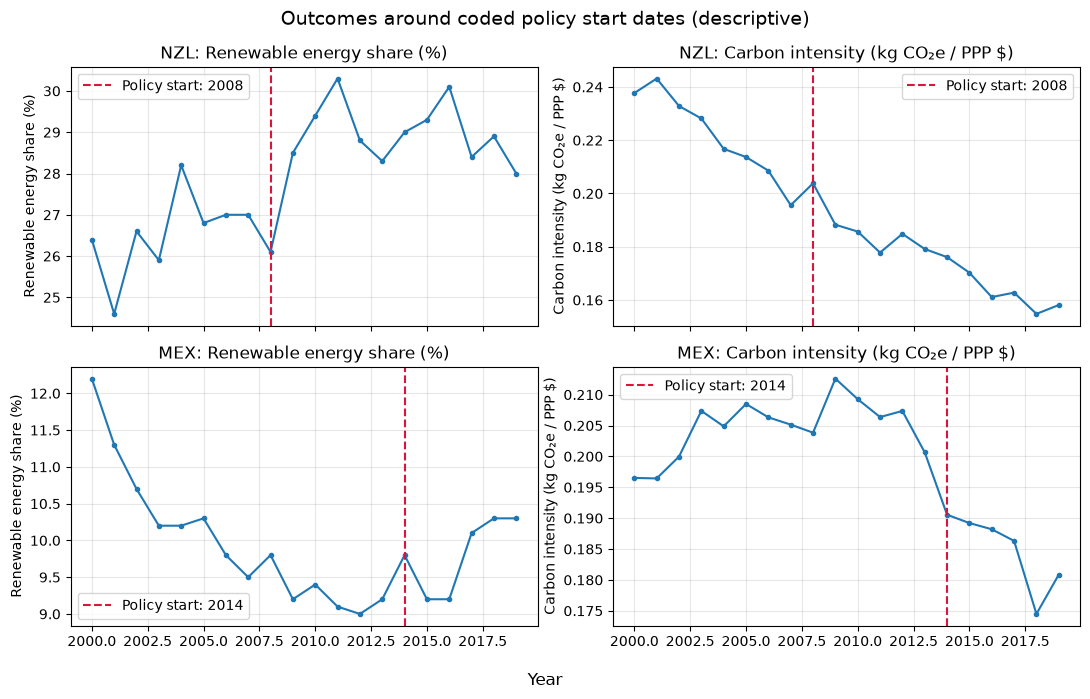

그래프 저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/nzl_mex_policy_outcomes_draft.png


In [8]:
cases = [("NZL", 2008), ("MEX", 2014)]
outcomes = [
    ("renewable_share", "Renewable energy share (%)"),
    ("carbon_intensity", "Carbon intensity (kg CO₂e / PPP $)")
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)

for row, (country, start_year) in enumerate(cases):
    country_data = panel[panel["country_code"] == country]

    for col, (variable, label) in enumerate(outcomes):
        ax = axes[row, col]
        ax.plot(
            country_data["year"],
            country_data[variable],
            marker="o",
            markersize=3
        )
        ax.axvline(
            start_year,
            color="crimson",
            linestyle="--",
            label=f"Policy start: {start_year}"
        )
        ax.set_title(f"{country}: {label}")
        ax.set_ylabel(label)
        ax.grid(alpha=0.3)
        ax.legend()

fig.supxlabel("Year")
fig.suptitle("Outcomes around coded policy start dates (descriptive)", fontsize=14)
fig.tight_layout()

chart_file = project / "outputs" / "nzl_mex_policy_outcomes_draft.png"
fig.savefig(chart_file, dpi=200, bbox_inches="tight")
plt.show()

print("그래프 저장 완료:", chart_file)

In [9]:
from pathlib import Path
import pandas as pd

project = Path.home() / "Documents" / "BSE_Climate_Policy"

panel = pd.read_csv(
    project / "processed_data" /
    "research_panel_draft_with_climate_patents_2000_2019.csv"
)

summary = (
    panel.sort_values(["country_code", "year"])
    .groupby("country_code")
    .agg(
        usable_years=("CPU", "count"),
        avg_CPU=("CPU", "mean"),
        renewable_2000=("renewable_share", "first"),
        renewable_2019=("renewable_share", "last"),
        climate_patents_2000=("climate_patents", "first"),
        climate_patents_2019=("climate_patents", "last"),
    )
    .reset_index()
)

summary["renewable_change_pp"] = (
    summary["renewable_2019"] - summary["renewable_2000"]
)

summary = summary.round(1)
display(summary)

output_file = project / "outputs" / "country_summary_draft.csv"
summary.to_csv(output_file, index=False)
print("저장 완료:", output_file)

,country_code,usable_years,avg_CPU,renewable_2000,renewable_2019,climate_patents_2000,climate_patents_2019,renewable_change_pp
0,AUS,20,105.6,8.4,10.3,138.7,224.8,1.9
1,CAN,16,79.0,20.3,22.4,256.5,706.3,2.1
2,DEU,19,53.7,3.7,17.1,1843.9,4064.2,13.4
3,ESP,20,56.1,7.9,16.7,54.7,228.5,8.8
4,FRA,19,49.5,9.3,15.5,478.2,1711.1,6.2
5,GBR,20,71.1,1.0,11.4,415.5,996.8,10.4
6,IRL,17,60.0,2.0,12.3,16.0,73.5,10.3
7,ITA,20,94.4,5.1,17.3,190.9,538.7,12.2
8,MEX,16,81.9,12.2,10.3,4.0,26.5,-1.9
9,NZL,20,78.1,26.4,28.0,14.8,39.3,1.6


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/country_summary_draft.csv


In [10]:
summary = summary.rename(columns={"usable_years": "years_with_CPU"})

analysis_years = (
    panel.assign(
        usable=panel["CPU"].notna() & panel["CarbonPrice_draft"].notna()
    )
    .groupby("country_code")["usable"]
    .sum()
    .rename("analysis_usable_years")
    .reset_index()
)

summary = summary.merge(
    analysis_years,
    on="country_code",
    validate="one_to_one"
)

display(summary[["country_code", "years_with_CPU", "analysis_usable_years"]])

output_file = project / "outputs" / "country_summary_draft.csv"
summary.to_csv(output_file, index=False)
print("수정해서 저장 완료:", output_file)

,country_code,years_with_CPU,analysis_usable_years
0,AUS,20,19
1,CAN,16,16
2,DEU,19,19
3,ESP,20,20
4,FRA,19,19
5,GBR,20,20
6,IRL,17,17
7,ITA,20,20
8,MEX,16,16
9,NZL,20,20


수정해서 저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/country_summary_draft.csv


In [11]:
from pathlib import Path
import pandas as pd

project = Path.home() / "Documents" / "BSE_Climate_Policy"

panel = pd.read_csv(
    project / "processed_data" /
    "research_panel_draft_with_climate_patents_2000_2019.csv"
)

analysis_columns = [
    "CPU",
    "CarbonPrice_draft",
    "renewable_share",
    "climate_patents",
    "gdp_per_capita",
    "trade_pct_gdp",
    "industry_pct_gdp",
    "carbon_intensity",
]

# 제외되는 국가·연도를 먼저 확인
excluded = panel.loc[
    panel[analysis_columns].isna().any(axis=1),
    ["country_code", "year"] + analysis_columns
]

print("제외되는 행:", len(excluded))
display(excluded[["country_code", "year", "CPU", "CarbonPrice_draft"]])

# 빈칸이 없는 행만 분석용으로 저장
analysis_sample = (
    panel.dropna(subset=analysis_columns)
    .sort_values(["country_code", "year"])
    .reset_index(drop=True)
)

print("분석용 행 수:", len(analysis_sample))
print("국가 수:", analysis_sample["country_code"].nunique())
print(
    "국가·연도 중복:",
    analysis_sample.duplicated(["country_code", "year"]).sum()
)

output_file = (
    project / "processed_data" /
    "analysis_sample_draft_2000_2019.csv"
)
analysis_sample.to_csv(output_file, index=False)
print("저장 완료:", output_file)

제외되는 행: 14


,country_code,year,CPU,CarbonPrice_draft
14,AUS,2014,107.854574,NaN
20,CAN,2000,NaN,0.0
21,CAN,2001,NaN,0.0
22,CAN,2002,NaN,0.0
23,CAN,2003,NaN,0.0
40,DEU,2000,NaN,0.0
80,FRA,2000,NaN,0.0
120,IRL,2000,NaN,0.0
121,IRL,2001,NaN,0.0
122,IRL,2002,NaN,0.0


분석용 행 수: 206
국가 수: 11
국가·연도 중복: 0
저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/processed_data/analysis_sample_draft_2000_2019.csv


In [12]:
variables = [
    "CPU", "CarbonPrice_draft", "renewable_share",
    "climate_patents", "gdp_per_capita",
    "trade_pct_gdp", "industry_pct_gdp",
    "carbon_intensity"
]

stats = (
    analysis_sample[variables]
    .describe()
    .loc[["count", "mean", "std", "min", "max"]]
    .T
    .round(2)
)

display(stats)

output_file = project / "outputs" / "analysis_descriptive_stats_draft.csv"
stats.to_csv(output_file)
print("저장 완료:", output_file)

,count,mean,std,min,max
CPU,206.0,73.74,39.56,18.02,261.23
CarbonPrice_draft,206.0,0.54,0.50,0.00,1.00
renewable_share,206.0,11.98,7.25,0.80,30.30
climate_patents,206.0,1218.94,2021.34,14.50,9235.88
gdp_per_capita,206.0,39108.34,12945.50,9074.12,76485.64
trade_pct_gdp,206.0,66.34,40.66,22.29,257.65
industry_pct_gdp,206.0,23.83,4.70,16.73,38.44
carbon_intensity,206.0,0.20,0.08,0.08,0.41


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/analysis_descriptive_stats_draft.csv


In [13]:
print("무역 비중이 가장 높은 5개 행")
display(
    analysis_sample.nlargest(5, "trade_pct_gdp")[
        ["country_code", "year", "trade_pct_gdp"]
    ]
)

print("기후 특허 수가 가장 높은 5개 행")
display(
    analysis_sample.nlargest(5, "climate_patents")[
        ["country_code", "year", "climate_patents"]
    ]
)

무역 비중이 가장 높은 5개 행


,country_code,year,trade_pct_gdp
129,IRL,2019,257.652773
126,IRL,2016,239.708528
127,IRL,2017,233.304083
125,IRL,2015,223.702938
128,IRL,2018,222.453716


기후 특허 수가 가장 높은 5개 행


,country_code,year,climate_patents
199,USA,2013,9235.882341
198,USA,2012,8673.897619
202,USA,2016,8467.374206
200,USA,2014,8332.146825
201,USA,2015,8324.709524


In [14]:
import numpy as np

analysis_sample = analysis_sample.copy()

analysis_sample["log_climate_patents"] = np.log1p(
    analysis_sample["climate_patents"]
)

print("기후 특허 원값과 로그값:")
display(
    analysis_sample[
        ["country_code", "year", "climate_patents", "log_climate_patents"]
    ].head()
)

output_file = (
    project / "processed_data" /
    "analysis_sample_draft_2000_2019.csv"
)
analysis_sample.to_csv(output_file, index=False)
print("로그 변수 추가 후 저장 완료:", output_file)

기후 특허 원값과 로그값:


,country_code,year,climate_patents,log_climate_patents
0,AUS,2000,138.750000,4.939855
1,AUS,2001,167.900000,5.129307
2,AUS,2002,160.933333,5.087185
3,AUS,2003,179.233333,5.194252
4,AUS,2004,213.800000,5.369707


로그 변수 추가 후 저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/processed_data/analysis_sample_draft_2000_2019.csv


In [15]:
policy_summary = (
    analysis_sample
    .groupby(["country_code", "CarbonPrice_draft"])
    .agg(
        years=("year", "count"),
        avg_renewable_share=("renewable_share", "mean"),
        avg_log_climate_patents=("log_climate_patents", "mean"),
    )
    .round(2)
    .reset_index()
)

display(policy_summary)

output_file = project / "outputs" / "policy_status_summary_draft.csv"
policy_summary.to_csv(output_file, index=False)
print("저장 완료:", output_file)

,country_code,CarbonPrice_draft,years,avg_renewable_share,avg_log_climate_patents
0,AUS,0.0,17,8.19,5.32
1,AUS,1.0,2,8.75,5.40
2,CAN,0.0,15,21.83,6.34
3,CAN,1.0,1,22.40,6.56
4,DEU,0.0,4,5.00,7.56
5,DEU,1.0,15,12.65,8.16
6,ESP,0.0,5,8.22,4.15
7,ESP,1.0,15,13.84,5.48
8,FRA,0.0,4,8.95,6.30
9,FRA,1.0,15,12.13,7.11


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/policy_status_summary_draft.csv


In [16]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 7.3 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 12.3 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.


In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

project = Path.home() / "Documents" / "BSE_Climate_Policy"

data = pd.read_csv(
    project / "processed_data" / "analysis_sample_draft_2000_2019.csv"
)

# CPU가 평균보다 10포인트 높거나 낮을 때를 기준으로 해석하기 쉽게 변환
data["CPU_10c"] = (data["CPU"] - data["CPU"].mean()) / 10
data["log_gdp_per_capita"] = np.log(data["gdp_per_capita"])

formula = (
    "renewable_share ~ CarbonPrice_draft * CPU_10c"
    " + log_gdp_per_capita + trade_pct_gdp + industry_pct_gdp"
    " + C(country_code) + C(year)"
)

model = smf.ols(formula, data=data).fit(
    cov_type="cluster",
    cov_kwds={"groups": data["country_code"], "use_correction": True},
    use_t=True
)

terms = [
    "CarbonPrice_draft",
    "CPU_10c",
    "CarbonPrice_draft:CPU_10c",
]

results = pd.DataFrame({
    "coefficient": model.params[terms],
    "standard_error": model.bse[terms],
    "p_value": model.pvalues[terms],
}).round(4)

print("분석 행 수:", int(model.nobs))
print("국가 수:", data["country_code"].nunique())
display(results)

분석 행 수: 206
국가 수: 11


,coefficient,standard_error,p_value
CarbonPrice_draft,-0.2631,0.9101,0.7784
CPU_10c,-0.1433,0.0539,0.0239
CarbonPrice_draft:CPU_10c,0.0744,0.0778,0.3615


In [18]:
data["log_climate_patents"] = np.log1p(data["climate_patents"])

patent_formula = formula.replace(
    "renewable_share ~",
    "log_climate_patents ~"
)

patent_model = smf.ols(patent_formula, data=data).fit(
    cov_type="cluster",
    cov_kwds={"groups": data["country_code"], "use_correction": True},
    use_t=True
)

patent_results = pd.DataFrame({
    "coefficient": patent_model.params[terms],
    "standard_error": patent_model.bse[terms],
    "p_value": patent_model.pvalues[terms],
}).round(4)

print("분석 행 수:", int(patent_model.nobs))
display(patent_results)

분석 행 수: 206


,coefficient,standard_error,p_value
CarbonPrice_draft,0.0761,0.0874,0.4041
CPU_10c,-0.0054,0.0106,0.6222
CarbonPrice_draft:CPU_10c,0.0030,0.0109,0.7892


In [19]:
intensity_formula = formula.replace(
    "renewable_share ~",
    "carbon_intensity ~"
)

intensity_model = smf.ols(intensity_formula, data=data).fit(
    cov_type="cluster",
    cov_kwds={"groups": data["country_code"], "use_correction": True},
    use_t=True
)

intensity_results = pd.DataFrame({
    "coefficient": intensity_model.params[terms],
    "standard_error": intensity_model.bse[terms],
    "p_value": intensity_model.pvalues[terms],
}).round(4)

print("분석 행 수:", int(intensity_model.nobs))
display(intensity_results)

분석 행 수: 206


,coefficient,standard_error,p_value
CarbonPrice_draft,0.0196,0.0074,0.0245
CPU_10c,-0.0001,0.0005,0.8220
CarbonPrice_draft:CPU_10c,-0.0001,0.0005,0.7961


In [20]:
models = {
    "renewable_share": model,
    "log_climate_patents": patent_model,
    "carbon_intensity": intensity_model,
}

rows = []
for outcome, fitted in models.items():
    for term in terms:
        rows.append({
            "outcome": outcome,
            "term": term,
            "coefficient": fitted.params[term],
            "standard_error": fitted.bse[term],
            "p_value": fitted.pvalues[term],
            "observations": int(fitted.nobs),
        })

model_summary = pd.DataFrame(rows)
display(model_summary.round(4))

output_file = project / "outputs" / "exploratory_models_draft.csv"
model_summary.to_csv(output_file, index=False)
print("저장 완료:", output_file)

,outcome,term,coefficient,standard_error,p_value,observations
0,renewable_share,CarbonPrice_draft,-0.2631,0.9101,0.7784,206
1,renewable_share,CPU_10c,-0.1433,0.0539,0.0239,206
2,renewable_share,CarbonPrice_draft:CPU_10c,0.0744,0.0778,0.3615,206
3,log_climate_patents,CarbonPrice_draft,0.0761,0.0874,0.4041,206
4,log_climate_patents,CPU_10c,-0.0054,0.0106,0.6222,206
5,log_climate_patents,CarbonPrice_draft:CPU_10c,0.0030,0.0109,0.7892,206
6,carbon_intensity,CarbonPrice_draft,0.0196,0.0074,0.0245,206
7,carbon_intensity,CPU_10c,-0.0001,0.0005,0.8220,206
8,carbon_intensity,CarbonPrice_draft:CPU_10c,-0.0001,0.0005,0.7961,206


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/exploratory_models_draft.csv


In [21]:
outcome_formulas = {
    "renewable_share": formula,
    "log_climate_patents": patent_formula,
    "carbon_intensity": intensity_formula,
}

interaction = "CarbonPrice_draft:CPU_10c"
checks = []

# 11개국 전체 결과
for outcome, fitted in models.items():
    checks.append({
        "excluded_country": "NONE",
        "outcome": outcome,
        "interaction_coefficient": fitted.params[interaction],
    })

# 국가를 하나씩 제외한 결과
for country in sorted(data["country_code"].unique()):
    subset = data[data["country_code"] != country]

    for outcome, outcome_formula in outcome_formulas.items():
        fitted = smf.ols(outcome_formula, data=subset).fit()

        checks.append({
            "excluded_country": country,
            "outcome": outcome,
            "interaction_coefficient": fitted.params[interaction],
        })

sensitivity = pd.DataFrame(checks)

comparison = sensitivity.pivot(
    index="excluded_country",
    columns="outcome",
    values="interaction_coefficient"
)

display(comparison.round(4))

output_file = project / "outputs" / "leave_one_country_out_draft.csv"
sensitivity.to_csv(output_file, index=False)
print("저장 완료:", output_file)

outcome,carbon_intensity,log_climate_patents,renewable_share
excluded_country,,,
AUS,0.0002,-0.0068,0.0531
CAN,0.0000,0.0038,0.0688
DEU,-0.0003,0.0011,0.0948
ESP,-0.0000,0.0077,0.0681
FRA,-0.0003,0.0016,0.0591
GBR,0.0000,0.0023,0.0493
IRL,-0.0004,-0.0046,0.0331
ITA,-0.0002,0.0062,0.0233
MEX,-0.0003,0.0031,0.0774


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/leave_one_country_out_draft.csv


In [22]:
policy_term = "CarbonPrice_draft"

policy_check = [{
    "excluded_country": "NONE",
    "policy_coefficient": intensity_model.params[policy_term],
}]

for country in sorted(data["country_code"].unique()):
    subset = data[data["country_code"] != country]

    fitted = smf.ols(intensity_formula, data=subset).fit()

    policy_check.append({
        "excluded_country": country,
        "policy_coefficient": fitted.params[policy_term],
    })

policy_check = pd.DataFrame(policy_check)
display(policy_check.round(4))

,excluded_country,policy_coefficient
0,NONE,0.0196
1,AUS,0.0211
2,CAN,0.0212
3,DEU,0.0200
4,ESP,0.0194
5,FRA,0.0200
6,GBR,0.0199
7,IRL,0.0193
8,ITA,0.0193
9,MEX,0.0226


In [23]:
import pandas as pd

# 현재까지 사용한 잠정 코딩 기준
policy_basis = {
    "AUS": "Australia CPM (2012–2013); 2014 transition year left missing",
    "CAN": "Federal carbon pricing from 2019",
    "DEU": "EU ETS from 2005",
    "ESP": "EU ETS from 2005",
    "FRA": "EU ETS from 2005",
    "GBR": "EU ETS from 2005",
    "IRL": "EU ETS from 2005",
    "ITA": "EU ETS from 2005",
    "MEX": "National carbon tax from 2014",
    "NZL": "New Zealand ETS from 2008",
    "USA": "State-level policies excluded from this draft definition",
}

audit_rows = []

# 결측 연도까지 볼 수 있도록 206행 분석 표본이 아닌 220행 원본 사용
for country, group in panel.groupby("country_code"):
    treated_years = group.loc[
        group["CarbonPrice_draft"].eq(1), "year"
    ]

    audit_rows.append({
        "country_code": country,
        "coding_basis_draft": policy_basis[country],
        "years_coded_0": int(group["CarbonPrice_draft"].eq(0).sum()),
        "years_coded_1": int(group["CarbonPrice_draft"].eq(1).sum()),
        "years_missing": int(group["CarbonPrice_draft"].isna().sum()),
        "first_year_coded_1": (
            int(treated_years.min()) if len(treated_years) else pd.NA
        ),
    })

policy_audit = pd.DataFrame(audit_rows)
display(policy_audit)

output_file = project / "outputs" / "policy_coding_audit_draft.csv"
policy_audit.to_csv(output_file, index=False)
print("저장 완료:", output_file)

,country_code,coding_basis_draft,years_coded_0,years_coded_1,years_missing,first_year_coded_1
0,AUS,Australia CPM (2012–2013); 2014 transition yea...,17,2,1,2012
1,CAN,Federal carbon pricing from 2019,19,1,0,2019
2,DEU,EU ETS from 2005,5,15,0,2005
3,ESP,EU ETS from 2005,5,15,0,2005
4,FRA,EU ETS from 2005,5,15,0,2005
5,GBR,EU ETS from 2005,5,15,0,2005
6,IRL,EU ETS from 2005,5,15,0,2005
7,ITA,EU ETS from 2005,5,15,0,2005
8,MEX,National carbon tax from 2014,14,6,0,2014
9,NZL,New Zealand ETS from 2008,8,12,0,2008


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/policy_coding_audit_draft.csv


In [24]:
import pandas as pd

excel_file = project / "raw_data" / "carbon_pricing_raw_2605.xlsx"

price_preview = pd.read_excel(
    excel_file,
    sheet_name="Compliance_Price",
    header=None
)

print("시트 크기:", price_preview.shape)
display(price_preview.iloc[:12, :12])

시트 크기: (100, 43)


,0,1,2,3,4,5,6,7,8,9,10,11
0,"Data last updated April 1, 2026",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Unique ID,Name of the initiative,Instrument Type,Region,Income group,Metric,1990.0,1991.0,1992.0,1993.0,1994.0,1995.0
2,Tax_AL,Albania carbon tax,Carbon tax,Europe & Central Asia,Upper middle income,US$/tCO2e,NaN,NaN,NaN,NaN,NaN,NaN
3,Tax_CA_Alberta,Alberta carbon tax,Carbon tax,North America,High income,US$/tCO2e,NaN,NaN,NaN,NaN,NaN,NaN
4,ETS_CA_Alberta,Alberta TIER,ETS,North America,High income,US$/tCO2e,NaN,NaN,NaN,NaN,NaN,NaN
5,Tax_AN,Andorra carbon tax,Carbon tax,Europe & Central Asia,High income,US$/tCO2e,NaN,NaN,NaN,NaN,NaN,NaN
6,Tax_AR,Argentina carbon tax,Carbon tax,Latin America & Caribbean,Upper middle income,US$/tCO2e,NaN,NaN,NaN,NaN,NaN,NaN
7,ETS_AU1,Australia CPM,ETS,East Asia & Pacific,High income,US$/tCO2e,NaN,NaN,NaN,NaN,NaN,NaN
8,ETS_AU2,Australia Safeguard Mechanism,ETS,East Asia & Pacific,High income,US$/tCO2e,NaN,NaN,NaN,NaN,NaN,NaN
9,ETS_AT,Austria ETS,ETS,Europe & Central Asia,High income,US$/tCO2e,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
price = pd.read_excel(
    excel_file,
    sheet_name="Compliance_Price",
    header=1
)

year_cols = [
    col for col in price.columns
    if pd.notna(pd.to_numeric(col, errors="coerce"))
    and 2000 <= float(col) <= 2019
]

policy_ids = [
    "ETS_AU1", "Tax_CA", "ETS_CA", "ETS_EU",
    "Tax_FR", "Tax_IE", "Tax_MX", "ETS_NZ",
    "Tax_ES", "Tax_UK", "ETS_UK", "ETS_DE"
]

selected = price.loc[
    price["Unique ID"].isin(policy_ids),
    ["Unique ID", "Name of the initiative"] + year_cols
].copy()

checks = []
for _, row in selected.iterrows():
    available = [
        int(float(col)) for col in year_cols
        if pd.notna(row[col])
    ]

    checks.append({
        "Unique ID": row["Unique ID"],
        "Name": row["Name of the initiative"],
        "years_with_price_2000_2019": len(available),
        "first_price_year": min(available) if available else None,
        "last_price_year": max(available) if available else None,
    })

price_coverage = pd.DataFrame(checks)
display(price_coverage.sort_values("Unique ID"))
print("확인한 연도 열 수:", len(year_cols))

,Unique ID,Name,years_with_price_2000_2019,first_price_year,last_price_year
0,ETS_AU1,Australia CPM,3,2012.0,2014.0
2,ETS_CA,Canada federal OBPS,0,NaN,NaN
5,ETS_DE,Germany ETS,0,NaN,NaN
3,ETS_EU,EU ETS,15,2005.0,2019.0
8,ETS_NZ,New Zealand ETS,12,2008.0,2019.0
11,ETS_UK,UK ETS,0,NaN,NaN
1,Tax_CA,Canada federal fuel charge,1,2019.0,2019.0
9,Tax_ES,Spain carbon tax,6,2014.0,2019.0
4,Tax_FR,France carbon tax,6,2014.0,2019.0
6,Tax_IE,Ireland carbon tax,10,2010.0,2019.0


확인한 연도 열 수: 20


In [26]:
year_column = {
    int(float(col)): col for col in year_cols
}

years_to_check = [2012, 2013, 2014, 2015, 2019]

display(
    selected.loc[
        selected["Unique ID"].isin(
            ["ETS_AU1", "Tax_MX", "Tax_CA", "ETS_EU"]
        ),
        ["Unique ID", "Name of the initiative"]
        + [year_column[year] for year in years_to_check]
    ]
)

,Unique ID,Name of the initiative,2012,2013,2014,2015,2019
5,ETS_AU1,Australia CPM,23.924600,24.584508,22.370145,NaN,NaN
13,Tax_CA,Canada federal fuel charge,NaN,NaN,NaN,NaN,14.995876
24,ETS_EU,EU ETS,9.322488,6.043960,6.757100,7.689825,24.505716
47,Tax_MX,Mexico carbon tax,NaN,NaN,NaN,3.115362,2.888936


In [27]:
reference_id = {
    "AUS": "ETS_AU1",
    "CAN": "Tax_CA",
    "DEU": "ETS_EU",
    "ESP": "ETS_EU",
    "FRA": "ETS_EU",
    "GBR": "ETS_EU",
    "IRL": "ETS_EU",
    "ITA": "ETS_EU",
    "MEX": "Tax_MX",
    "NZL": "ETS_NZ",
    "USA": None,
}

reference_prices = (
    price.loc[
        price["Unique ID"].isin(
            {item for item in reference_id.values() if item is not None}
        ),
        ["Unique ID"] + year_cols
    ]
    .melt(
        id_vars="Unique ID",
        value_vars=year_cols,
        var_name="year",
        value_name="reference_price_usd_tco2e"
    )
    .rename(columns={"Unique ID": "reference_instrument_id"})
)

reference_prices["year"] = (
    reference_prices["year"].astype(float).astype(int)
)
reference_prices["reference_price_usd_tco2e"] = pd.to_numeric(
    reference_prices["reference_price_usd_tco2e"],
    errors="coerce"
)

price_panel = panel[
    ["country_code", "year", "CarbonPrice_draft"]
].copy()

price_panel["reference_instrument_id"] = (
    price_panel["country_code"].map(reference_id)
)

price_panel = price_panel.merge(
    reference_prices,
    on=["reference_instrument_id", "year"],
    how="left",
    validate="many_to_one"
)

print("행 수:", len(price_panel))
print("국가별 가격 관측 연도:")
display(
    price_panel.groupby("country_code")[
        "reference_price_usd_tco2e"
    ].count()
)

print("코딩 차이를 확인할 두 행:")
display(
    price_panel.loc[
        ((price_panel["country_code"] == "AUS") |
         (price_panel["country_code"] == "MEX")) &
        (price_panel["year"] == 2014)
    ]
)

output_file = (
    project / "processed_data" /
    "carbon_price_reference_observed_2000_2019.csv"
)
price_panel.to_csv(output_file, index=False)
print("저장 완료:", output_file)

행 수: 220
국가별 가격 관측 연도:


country_code
AUS     3
CAN     1
DEU    15
ESP    15
FRA    15
GBR    15
IRL    15
ITA    15
MEX     5
NZL    12
USA     0
Name: reference_price_usd_tco2e, dtype: int64

코딩 차이를 확인할 두 행:


,country_code,year,CarbonPrice_draft,reference_instrument_id,reference_price_usd_tco2e
14,AUS,2014,NaN,ETS_AU1,22.370145
174,MEX,2014,1.0,Tax_MX,NaN


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/processed_data/carbon_price_reference_observed_2000_2019.csv


In [28]:
price_panel = price_panel.rename(columns={
    "reference_price_usd_tco2e":
    "reference_price_apr1_usd_tco2e"
})

output_file = (
    project / "processed_data" /
    "carbon_price_reference_observed_2000_2019.csv"
)

price_panel.to_csv(output_file, index=False)
print("열 이름 수정 완료:", output_file)
display(price_panel.head())

열 이름 수정 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/processed_data/carbon_price_reference_observed_2000_2019.csv


,country_code,year,CarbonPrice_draft,reference_instrument_id,reference_price_apr1_usd_tco2e
0,AUS,2000,0.0,ETS_AU1,NaN
1,AUS,2001,0.0,ETS_AU1,NaN
2,AUS,2002,0.0,ETS_AU1,NaN
3,AUS,2003,0.0,ETS_AU1,NaN
4,AUS,2004,0.0,ETS_AU1,NaN


In [29]:
dictionary_file = project / "variable_dictionary_draft.md"

heading = "## Reference carbon price (draft)"
note = """
## Reference carbon price (draft)

- File: `processed_data/carbon_price_reference_observed_2000_2019.csv`
- Variable: `reference_price_apr1_usd_tco2e`
- Definition: Nominal price in US dollars per tCO2e for the selected reference
  carbon pricing instrument, generally measured on April 1 of each year
  (or the latest available date before April 1).
- Source: World Bank Carbon Pricing Dashboard, `Compliance_Price` sheet.
  Methodology: https://carbonpricingdashboard.worldbank.org/about-us
- This is an instrument-level reference price, not a national annual average
  or an economy-wide effective carbon price. EU ETS prices are shared across
  the six countries assigned `ETS_EU`; other instruments can coexist.
- Missing price means no price observation for this selected instrument.
  It must not automatically be converted to zero or to policy non-adoption.
- Australia 2014: a CPM price is observed, while `CarbonPrice_draft` is
  missing because 2014 is treated as a transition year.
- Mexico 2014: `CarbonPrice_draft` is 1, while this price is missing.
- The preliminary regression models use `CarbonPrice_draft`, not this
  reference-price variable.
"""

existing = dictionary_file.read_text(encoding="utf-8")

if heading not in existing:
    dictionary_file.write_text(
        existing.rstrip() + "\n\n" + note.strip() + "\n",
        encoding="utf-8"
    )
    print("변수 설명 추가 완료:", dictionary_file)
else:
    print("이미 설명이 들어 있어요:", dictionary_file)

변수 설명 추가 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/variable_dictionary_draft.md


In [30]:
from pathlib import Path
import pandas as pd

project = Path.home() / "Documents" / "BSE_Climate_Policy"

results = pd.read_csv(
    project / "outputs" / "exploratory_models_draft.csv"
)

interaction = results[
    results["term"] == "CarbonPrice_draft:CPU_10c"
].set_index("outcome")

def result_line(outcome, label):
    row = interaction.loc[outcome]
    return (
        f"- {label}: 상호작용 계수 {row['coefficient']:.4f}, "
        f"p값 {row['p_value']:.4f}"
    )

memo = f"""# Research progress memo — draft

## Data assembled

- Scope: 11 countries, 2000–2019.
- Full country-year panel: 220 rows.
- Preliminary analysis sample: 206 rows. Thirteen early CPU observations
  and Australia 2014 are excluded because required values are missing.
- Outcomes examined: renewable energy share, climate mitigation patents,
  and carbon intensity.
- The carbon pricing indicator is a provisional 0/1 policy definition.
  Instrument-level April 1 reference prices are stored separately.

## Preliminary analysis

Country and year fixed effects were included. Standard errors were clustered
by country. The CPU–policy interaction results were:

{result_line("renewable_share", "Renewable energy share")}
{result_line("log_climate_patents", "Log climate patents")}
{result_line("carbon_intensity", "Carbon intensity")}

These are exploratory associations, not causal estimates. The current models
do not provide clear evidence that the CPU–outcome relationship differs by
the provisional carbon pricing indicator.

## Data and design issues

- Six countries share the EU ETS start year of 2005.
- The US is coded 0 throughout because subnational policies are outside
  the current policy definition.
- Australia 2014 is a transition year with a recorded CPM reference price,
  but its provisional policy indicator is missing.
- Mexico 2014 is coded as a policy year, but its reference price is missing.
- Canada has only one treated year in the 2000–2019 analysis period.
- Reference prices are instrument-level nominal prices generally observed
  on April 1, not national annual average prices.
- Leave-one-country-out checks suggest that the interaction estimates
  for patents and carbon intensity can change sign. Results involving
  the policy indicator are also sensitive to the comparison sample.

## Decisions TBD

1. Confirm the policy indicator's geographic scope and treatment of
   overlapping instruments.
2. Decide whether the main question is about policy adoption, price level,
   or both; keep these as separate variables.
3. Select a defensible comparison and inference strategy before making
   any causal claim.
4. Agree on the primary outcome and any lag between policy, uncertainty,
   and outcomes.
"""

output_file = project / "outputs" / "research_progress_memo_draft.md"
output_file.write_text(memo, encoding="utf-8")

print("연구 메모 저장 완료:", output_file)
print("상호작용 결과 3개가 들어갔는지 확인:")
print("\n".join(line for line in memo.splitlines() if "상호작용 계수" in line))

연구 메모 저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/research_progress_memo_draft.md
상호작용 결과 3개가 들어갔는지 확인:
- Renewable energy share: 상호작용 계수 0.0744, p값 0.3615
- Log climate patents: 상호작용 계수 0.0030, p값 0.7892
- Carbon intensity: 상호작용 계수 -0.0001, p값 0.7961


In [31]:
eu_countries = ["DEU", "ESP", "FRA", "GBR", "IRL", "ITA"]
non_eu_data = data[~data["country_code"].isin(eu_countries)].copy()

comparison_rows = []
interaction_term = "CarbonPrice_draft:CPU_10c"

for outcome, outcome_formula in outcome_formulas.items():
    non_eu_model = smf.ols(
        outcome_formula,
        data=non_eu_data
    ).fit()

    comparison_rows.append({
        "outcome": outcome,
        "all_11_coefficient": models[outcome].params[interaction_term],
        "non_eu_5_coefficient": non_eu_model.params[interaction_term],
        "non_eu_observations": int(non_eu_model.nobs),
    })

eu_sensitivity = pd.DataFrame(comparison_rows)

print("EU 제외 후 국가:", sorted(non_eu_data["country_code"].unique()))
display(eu_sensitivity.round(4))

output_file = project / "outputs" / "exclude_eu_sensitivity_draft.csv"
eu_sensitivity.to_csv(output_file, index=False)
print("저장 완료:", output_file)

EU 제외 후 국가: ['AUS', 'CAN', 'MEX', 'NZL', 'USA']


,outcome,all_11_coefficient,non_eu_5_coefficient,non_eu_observations
0,renewable_share,0.0744,-0.0469,91
1,log_climate_patents,0.0030,-0.0044,91
2,carbon_intensity,-0.0001,-0.0011,91


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/exclude_eu_sensitivity_draft.csv


In [32]:
memo_file = project / "outputs" / "research_progress_memo_draft.md"
heading = "## EU-group sensitivity"

addition = """
## EU-group sensitivity

Excluding the six countries assigned the EU ETS leaves five countries
(Australia, Canada, Mexico, New Zealand, and the United States) and
91 observations.

- Renewable share CPU–policy interaction: 0.0744 with all 11 countries;
  -0.0469 without the EU group.
- Log climate patents interaction: 0.0030 with all 11 countries;
  -0.0044 without the EU group.
- Carbon intensity interaction: approximately -0.0001 with all 11
  countries; -0.0011 without the EU group.

The change in direction for the first two outcomes shows that the
exploratory interaction estimates are sensitive to including the
shared EU ETS group. The five-country estimates are diagnostic only.
Neither set of estimates establishes a causal policy effect.
"""

current = memo_file.read_text(encoding="utf-8")

if heading not in current:
    memo_file.write_text(
        current.rstrip() + "\n\n" + addition.strip() + "\n",
        encoding="utf-8"
    )
    print("EU 민감도 결과를 연구 메모에 추가했어.")
else:
    print("EU 민감도 결과가 이미 메모에 있어.")

EU 민감도 결과를 연구 메모에 추가했어.


In [33]:
memo_file = project / "outputs" / "research_progress_memo_draft.md"
heading = "## Proposed research framing"

addition = """
## Proposed research framing

**Working question:** Across 11 countries in 2000–2019, how is climate
policy uncertainty (CPU) associated with renewable energy share,
climate mitigation patents, and carbon intensity? Does this association
differ according to the provisional national/supranational carbon
pricing indicator?

**Interpretation:** Current regressions describe conditional
associations. They do not identify the causal effect of CPU or carbon
pricing.

**Outcome roles (draft):**
- Renewable energy share: main outcome for the first analysis.
- Climate mitigation patents: complementary innovation outcome.
- Carbon intensity: complementary environmental outcome.

**Next design checks:**
1. Validate the geographic coverage and timing of the policy indicator.
2. Decide how to handle the six countries sharing EU ETS adoption.
3. Assess whether the small number of independently timed policy changes
   permits a credible causal design; otherwise retain a descriptive study.
4. Specify whether outcomes should respond in the same year or with a lag.
"""

current = memo_file.read_text(encoding="utf-8")

if heading not in current:
    memo_file.write_text(
        current.rstrip() + "\n\n" + addition.strip() + "\n",
        encoding="utf-8"
    )
    print("잠정 연구 질문과 결과변수 역할을 메모에 추가했어.")
else:
    print("이미 연구 질문이 메모에 있어.")

잠정 연구 질문과 결과변수 역할을 메모에 추가했어.


In [34]:
lag_check = panel.sort_values(
    ["country_code", "year"]
).copy()

for lag in [1, 2]:
    by_country = lag_check.groupby("country_code")

    previous_cpu = by_country["CPU"].shift(lag)
    previous_year = by_country["year"].shift(lag)

    # 바로 1년/2년 전 자료일 때만 사용
    lag_check[f"CPU_lag{lag}"] = previous_cpu.where(
        lag_check["year"] - previous_year == lag
    )

required_other_vars = [
    "CarbonPrice_draft",
    "renewable_share",
    "climate_patents",
    "carbon_intensity",
    "gdp_per_capita",
    "trade_pct_gdp",
    "industry_pct_gdp",
]

lag_counts = []

for label, cpu_column in [
    ("same_year", "CPU"),
    ("CPU_lag1", "CPU_lag1"),
    ("CPU_lag2", "CPU_lag2"),
]:
    usable = lag_check[
        required_other_vars + [cpu_column]
    ].notna().all(axis=1)

    lag_counts.append({
        "CPU_timing": label,
        "usable_rows": int(usable.sum()),
        "countries": lag_check.loc[
            usable, "country_code"
        ].nunique(),
    })

display(pd.DataFrame(lag_counts))

output_file = (
    project / "processed_data" /
    "panel_with_cpu_lags_draft_2000_2019.csv"
)
lag_check.to_csv(output_file, index=False)
print("시차 변수 저장 완료:", output_file)

,CPU_timing,usable_rows,countries
0,same_year,206,11
1,CPU_lag1,195,11
2,CPU_lag2,184,11


시차 변수 저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/processed_data/panel_with_cpu_lags_draft_2000_2019.csv


In [35]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

needed = [
    "CPU", "CPU_lag1", "CPU_lag2",
    "CarbonPrice_draft",
    "renewable_share", "climate_patents", "carbon_intensity",
    "gdp_per_capita", "trade_pct_gdp", "industry_pct_gdp",
]

common_sample = lag_check.dropna(subset=needed).copy()

common_sample["log_climate_patents"] = np.log1p(
    common_sample["climate_patents"]
)
common_sample["log_gdp_per_capita"] = np.log(
    common_sample["gdp_per_capita"]
)

# 세 CPU 변수 모두 같은 기준 평균으로 중심화
reference_mean = common_sample["CPU"].mean()

cpu_versions = {
    "same_year": "CPU",
    "lag_1_year": "CPU_lag1",
    "lag_2_years": "CPU_lag2",
}

outcomes = [
    "renewable_share",
    "log_climate_patents",
    "carbon_intensity",
]

lag_results = []

for timing, cpu_column in cpu_versions.items():
    common_sample["CPU_used_10c"] = (
        common_sample[cpu_column] - reference_mean
    ) / 10

    for outcome in outcomes:
        lag_formula = (
            f"{outcome} ~ CarbonPrice_draft * CPU_used_10c"
            " + log_gdp_per_capita + trade_pct_gdp + industry_pct_gdp"
            " + C(country_code) + C(year)"
        )

        fitted = smf.ols(
            lag_formula,
            data=common_sample
        ).fit()

        lag_results.append({
            "outcome": outcome,
            "CPU_timing": timing,
            "interaction_coefficient": fitted.params[
                "CarbonPrice_draft:CPU_used_10c"
            ],
            "observations": int(fitted.nobs),
        })

lag_comparison = pd.DataFrame(lag_results)

print("공통 표본:", len(common_sample), "행")
print("국가 수:", common_sample["country_code"].nunique())
display(lag_comparison.round(4))

output_file = project / "outputs" / "cpu_timing_common_sample_draft.csv"
lag_comparison.to_csv(output_file, index=False)
print("저장 완료:", output_file)

공통 표본: 184 행
국가 수: 11


,outcome,CPU_timing,interaction_coefficient,observations
0,renewable_share,same_year,0.1410,184
1,log_climate_patents,same_year,0.0026,184
2,carbon_intensity,same_year,-0.0000,184
3,renewable_share,lag_1_year,0.1638,184
4,log_climate_patents,lag_1_year,0.0052,184
5,carbon_intensity,lag_1_year,-0.0004,184
6,renewable_share,lag_2_years,0.1449,184
7,log_climate_patents,lag_2_years,0.0044,184
8,carbon_intensity,lag_2_years,-0.0002,184


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/cpu_timing_common_sample_draft.csv


In [36]:
memo_file = project / "outputs" / "research_progress_memo_draft.md"
heading = "## CPU timing and sample sensitivity"

same_184 = lag_comparison.loc[
    (lag_comparison["outcome"] == "renewable_share") &
    (lag_comparison["CPU_timing"] == "same_year"),
    "interaction_coefficient"
].iloc[0]

lag1_184 = lag_comparison.loc[
    (lag_comparison["outcome"] == "renewable_share") &
    (lag_comparison["CPU_timing"] == "lag_1_year"),
    "interaction_coefficient"
].iloc[0]

lag2_184 = lag_comparison.loc[
    (lag_comparison["outcome"] == "renewable_share") &
    (lag_comparison["CPU_timing"] == "lag_2_years"),
    "interaction_coefficient"
].iloc[0]

addition = f"""
## CPU timing and sample sensitivity

- Same-year CPU is available for 206 complete analysis rows.
- One-year lagged CPU leaves 195 rows; two-year lagged CPU leaves 184.
  All three samples retain 11 countries.
- On the same 184-row sample, the renewable-share CPU–policy interaction
  coefficients are {same_184:.4f} for same-year CPU, {lag1_184:.4f}
  for one-year lagged CPU, and {lag2_184:.4f} for two-year lagged CPU.
- The same-year coefficient is 0.0744 on the earlier 206-row sample
  but {same_184:.4f} on the common 184-row sample. Sample selection
  therefore matters when comparing specifications.
- These timing checks report coefficient stability only; they do not
  establish statistical significance or causal effects.
"""

current = memo_file.read_text(encoding="utf-8")

if heading not in current:
    memo_file.write_text(
        current.rstrip() + "\n\n" + addition.strip() + "\n",
        encoding="utf-8"
    )
    print("표본·시차 결과를 연구 메모에 반영했어.")
else:
    print("이미 메모에 반영돼 있어.")

표본·시차 결과를 연구 메모에 반영했어.


In [37]:
patent_check = panel[
    ["country_code", "year", "green_patents", "climate_patents"]
].copy()

print("전체 행:", len(patent_check))
print("특허 변수 결측치:")
print(patent_check[["green_patents", "climate_patents"]].isna().sum())

larger_climate = patent_check[
    patent_check["climate_patents"] > patent_check["green_patents"]
]

print("climate_patents가 green_patents보다 큰 행:", len(larger_climate))
display(larger_climate.head(10))

전체 행: 220
특허 변수 결측치:
green_patents      0
climate_patents    0
dtype: int64
climate_patents가 green_patents보다 큰 행: 0


,country_code,year,green_patents,climate_patents


In [38]:
from collections import Counter
import pandas as pd

raw_file = project / "raw_data" / "oecd_patents_raw.csv"
tech_counts = Counter()

for chunk in pd.read_csv(
    raw_file,
    usecols=[
        "REF_AREA", "TIME_PERIOD", "TECH",
        "UNIT_MEASURE", "SIZE", "SEX"
    ],
    chunksize=100_000,
    low_memory=False
):
    selected_rows = chunk[
        chunk["REF_AREA"].isin(panel["country_code"].unique()) &
        chunk["TIME_PERIOD"].between(2000, 2019) &
        chunk["UNIT_MEASURE"].eq("PATN") &
        chunk["SIZE"].eq("TWO") &
        chunk["SEX"].eq("_T")
    ]

    tech_counts.update(selected_rows["TECH"].value_counts().to_dict())

print("해당 조건의 TECH 코드와 행 수:")
print(tech_counts.most_common(30))

해당 조건의 TECH 코드와 행 수:
[('MAN_WAT_TR', 220), ('MAN_WAT', 220), ('MAN_WA', 220), ('MAN', 220), ('ADAPT', 220), ('ENV_PAT', 220), ('TOT', 220), ('GOODS', 220), ('CCM', 220), ('MAN_AIR', 219), ('ADAPT_HEALTH_DIS', 218), ('ADAPT_HEALTH', 218), ('ENE', 218), ('ADAPT_WATRES', 217), ('OCEAN', 217), ('ENE_RE', 217), ('BUILD', 217), ('WAT_WASTE', 217), ('TRA', 217), ('ENE_ENA', 217), ('ADAPT_AGR', 216), ('BUILD_ENE', 215), ('MAN_WA_MA', 214), ('TRA_RO', 214), ('GOODS_CHEM', 213), ('WAT_WASTE_WASTE', 213), ('ENE_ENA_STO', 213), ('GOODS_PROD', 212), ('MAN_AIR_NC', 211), ('FOSSIL', 211)]


In [39]:
import numpy as np

total_parts = []

for chunk in pd.read_csv(
    raw_file,
    usecols=[
        "REF_AREA", "TIME_PERIOD", "TECH",
        "UNIT_MEASURE", "SIZE", "SEX", "OBS_VALUE"
    ],
    chunksize=100_000,
    low_memory=False
):
    selected_rows = chunk.loc[
        chunk["REF_AREA"].isin(panel["country_code"].unique()) &
        chunk["TIME_PERIOD"].between(2000, 2019) &
        chunk["TECH"].eq("TOT") &
        chunk["UNIT_MEASURE"].eq("PATN") &
        chunk["SIZE"].eq("TWO") &
        chunk["SEX"].eq("_T"),
        ["REF_AREA", "TIME_PERIOD", "OBS_VALUE"]
    ]

    total_parts.append(selected_rows)

total_patents = pd.concat(total_parts, ignore_index=True).rename(
    columns={
        "REF_AREA": "country_code",
        "TIME_PERIOD": "year",
        "OBS_VALUE": "total_patents",
    }
)

total_patents["total_patents"] = pd.to_numeric(
    total_patents["total_patents"],
    errors="coerce"
)

patent_shares = panel[
    ["country_code", "year", "green_patents", "climate_patents"]
].merge(
    total_patents,
    on=["country_code", "year"],
    how="left",
    validate="one_to_one"
)

patent_shares["climate_patent_share_pct"] = (
    patent_shares["climate_patents"]
    / patent_shares["total_patents"] * 100
)

print("행 수:", len(patent_shares))
print("전체 특허 결측:", patent_shares["total_patents"].isna().sum())
print("전체 특허가 0 이하인 행:",
      (patent_shares["total_patents"] <= 0).sum())
print("기후 특허가 전체 특허보다 큰 행:",
      (patent_shares["climate_patents"] >
       patent_shares["total_patents"]).sum())

display(patent_shares.head())

행 수: 220
전체 특허 결측: 0
전체 특허가 0 이하인 행: 0
기후 특허가 전체 특허보다 큰 행: 0


,country_code,year,green_patents,climate_patents,total_patents,climate_patent_share_pct
0,AUS,2000,207.750000,138.750000,2576.533333,5.385143
1,AUS,2001,214.650000,167.900000,2585.850000,6.493029
2,AUS,2002,220.100000,160.933333,2525.688095,6.371861
3,AUS,2003,235.042857,179.233333,2654.929762,6.750963
4,AUS,2004,306.633333,213.800000,2827.870238,7.560460


In [40]:
# 비중이 가능한 범위에 있는지 마지막으로 확인
assert patent_shares["climate_patent_share_pct"].between(0, 100).all()

share_file = (
    project / "processed_data" /
    "patent_shares_2000_2019.csv"
)
patent_shares.to_csv(share_file, index=False)

sample_file = (
    project / "processed_data" /
    "analysis_sample_draft_2000_2019.csv"
)
sample_with_share = pd.read_csv(sample_file)

sample_with_share = sample_with_share.merge(
    patent_shares[
        ["country_code", "year",
         "total_patents", "climate_patent_share_pct"]
    ],
    on=["country_code", "year"],
    how="left",
    validate="one_to_one"
)

print("분석 표본 행 수:", len(sample_with_share))
print(
    "새 비중 변수 결측:",
    sample_with_share["climate_patent_share_pct"].isna().sum()
)

display(
    sample_with_share[
        ["country_code", "year", "climate_patents",
         "total_patents", "climate_patent_share_pct"]
    ].head()
)

sample_with_share.to_csv(sample_file, index=False)
print("저장 완료:", share_file)
print("분석 파일 업데이트 완료:", sample_file)

분석 표본 행 수: 206
새 비중 변수 결측: 0


,country_code,year,climate_patents,total_patents,climate_patent_share_pct
0,AUS,2000,138.750000,2576.533333,5.385143
1,AUS,2001,167.900000,2585.850000,6.493029
2,AUS,2002,160.933333,2525.688095,6.371861
3,AUS,2003,179.233333,2654.929762,6.750963
4,AUS,2004,213.800000,2827.870238,7.560460


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/processed_data/patent_shares_2000_2019.csv
분석 파일 업데이트 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/processed_data/analysis_sample_draft_2000_2019.csv


In [41]:
share_changes = (
    patent_shares.loc[
        patent_shares["year"].isin([2000, 2019]),
        ["country_code", "year", "climate_patent_share_pct"]
    ]
    .pivot(
        index="country_code",
        columns="year",
        values="climate_patent_share_pct"
    )
    .rename(columns={
        2000: "share_2000_pct",
        2019: "share_2019_pct"
    })
)

share_changes["change_percentage_points"] = (
    share_changes["share_2019_pct"]
    - share_changes["share_2000_pct"]
)

display(share_changes.round(2))

output_file = (
    project / "outputs" /
    "climate_patent_share_changes_draft.csv"
)
share_changes.to_csv(output_file)
print("저장 완료:", output_file)

year,share_2000_pct,share_2019_pct,change_percentage_points
country_code,,,
AUS,5.39,8.76,3.37
CAN,5.71,10.92,5.21
DEU,6.07,13.25,7.18
ESP,4.29,10.08,5.79
FRA,4.91,14.36,9.45
GBR,4.08,10.22,6.14
IRL,3.42,8.94,5.51
ITA,3.90,8.56,4.66
MEX,2.39,7.66,5.27


저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/climate_patent_share_changes_draft.csv


In [42]:
data_share = pd.read_csv(
    project / "processed_data" /
    "analysis_sample_draft_2000_2019.csv"
)

data_share["CPU_10c"] = (
    data_share["CPU"] - data_share["CPU"].mean()
) / 10

data_share["log_gdp_per_capita"] = np.log(
    data_share["gdp_per_capita"]
)

share_formula = (
    "climate_patent_share_pct ~ CarbonPrice_draft * CPU_10c"
    " + log_gdp_per_capita + trade_pct_gdp + industry_pct_gdp"
    " + C(country_code) + C(year)"
)

share_model = smf.ols(
    share_formula,
    data=data_share
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": data_share["country_code"],
        "use_correction": True
    },
    use_t=True
)

share_model_results = pd.DataFrame({
    "coefficient": share_model.params[terms],
    "standard_error": share_model.bse[terms],
    "p_value": share_model.pvalues[terms],
}).round(4)

print("분석 행 수:", int(share_model.nobs))
display(share_model_results)

분석 행 수: 206


,coefficient,standard_error,p_value
CarbonPrice_draft,0.3668,0.3149,0.2711
CPU_10c,-0.0299,0.0605,0.6321
CarbonPrice_draft:CPU_10c,0.0300,0.0613,0.6349


In [43]:
result_file = project / "outputs" / "patent_share_model_draft.csv"

share_model_results.to_csv(result_file)
print("모형 결과 저장 완료:", result_file)

memo_file = project / "outputs" / "research_progress_memo_draft.md"
heading = "## Climate patent share check"

addition = f"""
## Climate patent share check

The OECD total-patent series (`TECH=TOT`) was extracted using the same
country, year, unit, family-size, and sex filters as the climate patent
count. Climate patent share is climate patents divided by total patents,
multiplied by 100.

All 220 country-year rows have a valid denominator. The climate patent
share rose between 2000 and 2019 in all 11 countries, including the US,
which is coded 0 throughout under the provisional policy definition.

In the exploratory 206-row fixed-effects model, the CPU–policy
interaction coefficient for climate patent share is
{share_model.params["CarbonPrice_draft:CPU_10c"]:.4f} percentage points
(p = {share_model.pvalues["CarbonPrice_draft:CPU_10c"]:.4f}).
This does not establish a policy effect. Both the patent count and share
are retained as distinct outcomes.
"""

current = memo_file.read_text(encoding="utf-8")

if heading not in current:
    memo_file.write_text(
        current.rstrip() + "\n\n" + addition.strip() + "\n",
        encoding="utf-8"
    )
    print("특허 비중 결과를 연구 메모에 반영했어.")
else:
    print("특허 비중 결과가 이미 메모에 있어.")

모형 결과 저장 완료: /Users/imsnmn/Documents/BSE_Climate_Policy/outputs/patent_share_model_draft.csv
특허 비중 결과를 연구 메모에 반영했어.
